# Task 3 Transfer learning

In [6]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

np.random.seed(42)
torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


## experimental setup choices


For the target task, I rotated the images by 90 degrees .
 This is a appropriate transfer learning because the source and target tasks are still the same, but the input distribution changes in a important way

I used only a small balanced target training set.Keeping the target set small makes the experiment more relevant, because it tests if knowledge from the source task can help when only a few target examples are available. 

the source model is  fc net previously trained in task 1 . It is also a meaningful choice for this experiment because a fully conn. network is sensitive to the spatial arrangement and this makes the transfer problem more visible and easier to study.

During training, I monitored validation accuracy at each epoch and saved the weights corresponding to the highest validation accuracy and then evaluated it on the test set.

For the transfer method, I adopted fine tuning starting from the source model weights. I compared different freezing strategies and learning rates, because after rotating the images some features learned on the source task may still be useful, while others need adaptation. If too many layers are frozen, the model may stay too close to the source task. If all layers are updated too freely, the model may lose the prior knowledge. For this reason comparing strong freezing, light freezing and no freezing is a good way to study how much adaptation we need. I also compared different learning rates to make updates more or less aggressive.

I use 3 types of freezing defined in the definitio of the class Deepnet:

`unfreeze_all()` trains the whole network again

`freeze_less()` freezes only the first block `fc1` + `bn1`, so the rest of the network is  trainable

`freeze_many()` freezes the first two blocks `fc1` + `bn1`, `fc2` + `bn2`


I repeat the experiments across multiple random seeds because target dataset ,intentionally  , is very small. With so few samples, the result can depend strongly on which images are selected and this give us a more strong results

In [ ]:
transform_standard = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))# I have to keep the same normalization for both source (trained on task_1) and target
                                                #to make sure to have the same preprocessing to get a more fair evaluation
])

transform_rotated = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: torch.rot90(x, k=-1, dims=[1, 2])),
    transforms.Normalize((0.1307,), (0.3081,)) # I have to keep the same normalization for both
])

source_train = datasets.MNIST(root="./data", train=True, download=True, transform=transform_standard)
source_test = datasets.MNIST(root="./data", train=False, download=True, transform=transform_standard)

target_train_full = datasets.MNIST(root="./data", train=True, download=True, transform=transform_rotated)
target_test = datasets.MNIST(root="./data", train=False, download=True, transform=transform_rotated)



source_test_loader = DataLoader(source_test, batch_size=1000, shuffle=False)

target_test_loader = DataLoader(target_test, batch_size=1000, shuffle=False)

#helper:balanced train/val split on target
''' helper:balanced train/val split on target
for each class, it randomly selects a fixed number of samples(30),then divides them:the first 20 in training and the remaining 10 to validation 
in this way every class contributes the same number of examples to both sets
Finally, it builds two DataLoaders: one for training, with shuffle, and one for validation, without it.
So in the end we have 200samples and  100 samples for training and validation respectively, with balanced class distribution
'''
def make_target_loaders(seed, n_train_per_classe =20, n_val_per_classe =10, bs=32):
    rng = np.random.default_rng(seed)
    labels = target_train_full.targets.numpy()

    train_indices =  []
    val_indices =   []

    total_per_class = n_train_per_classe+ n_val_per_classe

    for cls in range(10):
        class_indices = np.where(labels == cls)[0]

        chosen_indices = rng.choice(
            class_indices,
            size=total_per_class,
            replace=False       )
        

        train_part = chosen_indices[:n_train_per_classe]
        val_part = chosen_indices[n_train_per_classe:]

        for idx in train_part:
            train_indices.append(idx)

        for idx in val_part:
            val_indices.append(idx)

    train_subset = Subset(target_train_full, train_indices)
    val_subset = Subset(target_train_full, val_indices)

    train_loader = DataLoader(
        train_subset,
        batch_size=bs,
        shuffle=True
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=1000,
        shuffle=False
    )

    return train_loader, val_loader


### This is the identical DeepNet class from Task1
but I add the functions that I ll need later.

The key point for this task is that this architecture is sensitive to pixel position, so a 90° rotation creates a strong domain shift.

In [ ]:
class DeepNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 512)
        self.bn1 = nn.BatchNorm1d(512)
        self.fc2 = nn.Linear(512,256)
        self.bn2 = nn.BatchNorm1d(256)
        self.fc3 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.fc4 = nn.Linear(128,10)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)

        self.frozen_bn_layers = []

    def forward(self, x):
        x = x.view(x.size(0),-1)

        x = self.fc1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc3(x)
        x = self.bn3(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc4(x)
        return x

    def unfreeze_all(self):
        for p in self.parameters():
            p.requires_grad = True

        self.frozen_bn_layers = []
        self.bn1.train()
        self.bn2.train()
        self.bn3.train()

    def freeze_many(self):
        self.unfreeze_all()

        for p in self.fc1.parameters():
            p.requires_grad = False
        for p in self.bn1.parameters():
            p.requires_grad = False

        for p in self.fc2.parameters():
            p.requires_grad = False
        for p in self.bn2.parameters():
            p.requires_grad = False

        self.frozen_bn_layers = [self.bn1, self.bn2]

    def freeze_less(self):
        self.unfreeze_all()

        for p in self.fc1.parameters():
            p.requires_grad = False
        for p in self.bn1.parameters():
            p.requires_grad = False

        self.frozen_bn_layers = [self.bn1]

#keeps the frozen BatchNorm layers in evaluation mode, so their internal statistics are not updated

    def apply_frozen_bn_mode(self):
        for bn in self.frozen_bn_layers:
            bn.eval()




class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 16, 3, 1, 1)
        self.bn1 = nn.BatchNorm2d(16)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        self.fc = nn.Linear(16 * 14 * 14, 10)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

almost the same helper function for training and validation used in Task1 but with modifications


In [ ]:

def evaluate(model, loader):
    model = model.to(device)
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            pred = outputs.argmax(dim=1)

            correct += (pred == labels).sum().item()
            total += labels.size(0)

    return 100.0 * correct / total


def train_model(model, train_loader, val_loader, lr=1e-3, epochs=10):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    val_accuracies = []
    best_val = -1.0
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()

        # don t update Batchnorm stats of frozen layers, if "model" has apply_frozen_bn_mode method  
        if hasattr(model, "apply_frozen_bn_mode"):
            model.apply_frozen_bn_mode()

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

        val_acc = evaluate(model, val_loader)
        val_accuracies.append(val_acc)

        if val_acc > best_val:
            best_val = val_acc
            best_state = copy.deepcopy(model.state_dict())

        if (epoch % 10 == 0 or epoch == epochs - 1):
            print(f"epoch {epoch + 1} - val acc: {val_acc:.2f}%")

    model.load_state_dict(best_state)

    return val_accuracies, best_val

### Step 1: Source model

I use the one I trained in task_1: the DeepNet with regularization

In [10]:
print("uploading source model...")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_source = DeepNet()


model_source.load_state_dict(torch.load("weights_deep.pth", map_location=device))


model_source.eval()


source_test_acc = evaluate(model_source, source_test_loader)
print(f"Source test acc: {source_test_acc:.2f}%")

uploading source model...
Source test acc: 98.44%


### Step 2: Zero-shot performance

Here I evaluate the source model directly on rotated images without any fine tuning.  
This gives a reference point for how strong the domain shift is before transfer learn.

In [11]:
zs_acc = evaluate(model_source, target_test_loader)
print(f"Zero-shot acc on rotated TEST: {zs_acc:.2f}%")

Zero-shot acc on rotated TEST: 14.69%


Almost random-guess (10%), the domain shift is very strong

### Step 3: Transfer learning configurations

Starting from the source weights, I compare multiple transfer learning settings



In [ ]:
def apply_freeze(model, freeze_mode):
    model.unfreeze_all()

    if freeze_mode == "many":
        model.freeze_many()
    elif freeze_mode == "less":
        model.freeze_less()
    elif freeze_mode == "none":
        model.unfreeze_all()
    else:
        raise ValueError(f"Unknown freeze_mode: {freeze_mode}")


SEEDS = [0, 1, 2, 3, 4]

# with this dictionary it s easy to see the configuration that I want to try
TL_CONFIGS = {
    "freeze_many_lr1e-4": {"freeze": "many", "lr": 1e-4},
    "freeze_many_lr1e-3": {"freeze": "many", "lr": 1e-3},
    "freeze_less_lr1e-4": {"freeze": "less", "lr": 1e-4},
    "freeze_less_lr1e-3": {"freeze": "less", "lr": 1e-3},
    "no_freeze_lr1e-4": {"freeze": "none", "lr": 1e-4},
    "no_freeze_lr1e-3": {"freeze": "none", "lr": 1e-3},
}

results = {
    "scratch_fc": {"val": [], "test": []},
    "cnn_scratch": {"val": [], "test": []},
    **{name: {"val": [], "test": []} for name in TL_CONFIGS}
}



In [ ]:

curves_example = {}
for seed in SEEDS:
    print(f"\n---SEED {seed}---")


    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed_all(seed)


    target_train_loader, target_val_loader = make_target_loaders(seed=seed)

    #train DeepNet from scratch on the target domain
    print("training scratch FC")
    model_scratch = DeepNet()
    scratch_curve, scratch_best_val = train_model(
        model_scratch,
        target_train_loader,
        target_val_loader,
        epochs=50,
        lr=1e-3,
    )
    # evaluate the scratch model on the target test set
    scratch_test = evaluate(model_scratch, target_test_loader)
    results["scratch_fc"]["val"].append(scratch_best_val)
    results["scratch_fc"]["test"].append(scratch_test)


    # save the learning curve only for the first seed as a representative run
    if seed == SEEDS[0]:
        curves_example["scratch_fc"] = scratch_curve

    print(f"scratch_fc -> best val: {scratch_best_val:.2f}% | test: {scratch_test:.2f}%")

    #train a CNN  from scratch on the target domain
    print("training scratch CNN")
    cnn = SimpleCNN()
    cnn_curve, cnn_best_val = train_model(
        cnn,
        target_train_loader,
        target_val_loader,
        epochs=50,
        lr=1e-3,
    )
    # evaluate the scratch model on the target test set
    cnn_test = evaluate(cnn, target_test_loader)

    results["cnn_scratch"]["val"].append(cnn_best_val)
    results["cnn_scratch"]["test"].append(cnn_test)

    # Save the learning curve only for the first seed as a representative run
    if seed == SEEDS[0]:
        curves_example["cnn_scratch"] = cnn_curve

    print(f"cnn_scratch -> best val: {cnn_best_val:.2f}% | test: {cnn_test:.2f}%")

    # Transfer learning:
    # for each freeze/lr configuration defined in TL_CONFIGS..
    for name, cfg in TL_CONFIGS.items():
        print(f"{name} ...")
        model = DeepNet()
        model.load_state_dict(torch.load("weights_deep.pth", map_location=device))

        # Freeze part of the Deepnet according to the current TL 
        apply_freeze(model, cfg["freeze"])

        curve, best_val = train_model(
            model,
            target_train_loader,
            target_val_loader,
            epochs=50,
            lr=cfg["lr"], #use the learning rate according to the current TL 
        )

        test_acc = evaluate(model, target_test_loader)

        results[name]["val"].append(best_val)
        results[name]["test"].append(test_acc)

        if seed == SEEDS[0]:
            curves_example[name] = curve

        print(f"{name} -> best val: {best_val:.2f}% | test: {test_acc:.2f}%")


---SEED 0---
training scratch FC
scratch_fc -> best val: 85.00% | test: 79.20%
training scratch CNN
cnn_scratch -> best val: 88.00% | test: 83.28%
freeze_many_lr1e-4 ...
freeze_many_lr1e-4 -> best val: 24.00% | test: 24.51%
freeze_many_lr1e-3 ...
freeze_many_lr1e-3 -> best val: 69.00% | test: 72.65%
freeze_less_lr1e-4 ...
freeze_less_lr1e-4 -> best val: 46.00% | test: 43.20%
freeze_less_lr1e-3 ...
freeze_less_lr1e-3 -> best val: 79.00% | test: 79.08%
no_freeze_lr1e-4 ...
no_freeze_lr1e-4 -> best val: 59.00% | test: 62.04%
no_freeze_lr1e-3 ...
no_freeze_lr1e-3 -> best val: 82.00% | test: 83.12%

---SEED 1---
training scratch FC
scratch_fc -> best val: 83.00% | test: 82.49%
training scratch CNN
cnn_scratch -> best val: 79.00% | test: 80.91%
freeze_many_lr1e-4 ...
freeze_many_lr1e-4 -> best val: 14.00% | test: 24.53%
freeze_many_lr1e-3 ...
freeze_many_lr1e-3 -> best val: 76.00% | test: 71.63%
freeze_less_lr1e-4 ...
freeze_less_lr1e-4 -> best val: 44.00% | test: 41.56%
freeze_less_lr1e-3 

### Final results summary

This section summarizes the results across multiple runs, throught a simple average 
of best validation accuracy and  test accuracy 

In [14]:

print("\nFINAL SUMMARY OVER SEEDS")

for name, res in results.items():
    val_mean= np.mean(res["val"])
    test_mean= np.mean(res["test"])

    print(f"{name:20s}val = {val_mean:.2f}test = {test_mean:.2f}")



FINAL SUMMARY OVER SEEDS
scratch_fc          val = 83.80test = 80.82
cnn_scratch         val = 83.20test = 82.58
freeze_many_lr1e-4  val = 22.20test = 24.40
freeze_many_lr1e-3  val = 71.60test = 71.12
freeze_less_lr1e-4  val = 43.60test = 42.16
freeze_less_lr1e-3  val = 81.80test = 81.09
no_freeze_lr1e-4    val = 59.00test = 60.13
no_freeze_lr1e-3    val = 82.80test = 81.92


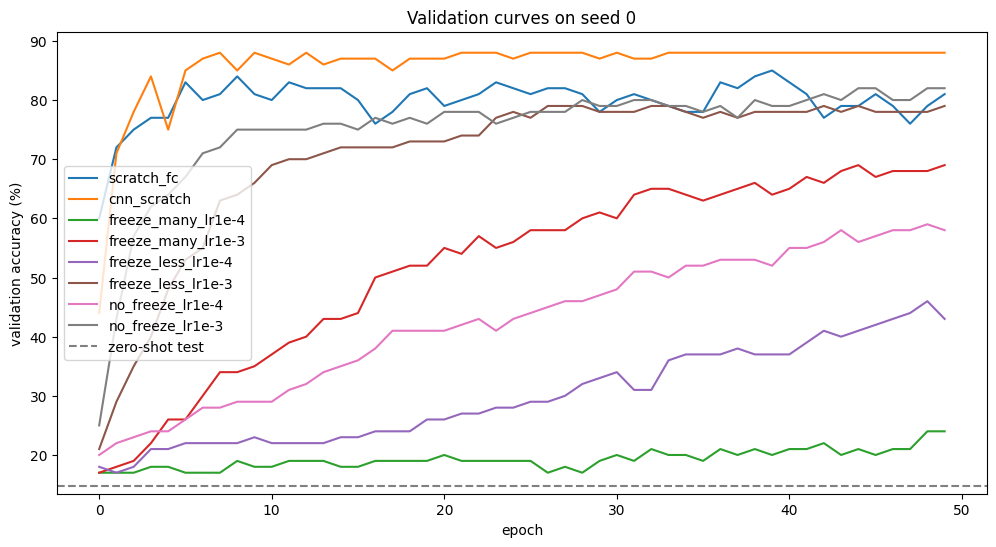

In [15]:
plt.figure(figsize=(12, 6))
for name, curve in curves_example.items():
    plt.plot(curve, label=name)

plt.axhline(zs_acc, color="gray", linestyle="--", label="zero-shot test")
plt.xlabel("epoch")
plt.ylabel("validation accuracy (%)")
plt.title("Validation curves on seed 0")
plt.legend()
plt.show()

## Conclusion



The first strong conclusion is that  domain shift is real: 98.44% on the original task, then 14.69% in zero-shot on the rotated test. This means that the features learned on the standard MNIST, in this fc architecture, are not rotation invariant at all

The second conclusion is that the new task, despite being different, remains learnable even with limited target data. The FC model trained from scratch on the small rotated dataset averages 80.82% on test, while the scratch CNN achieves 82.58%. therefore, 200 training examples are still enough to learn the new task from 0

third conclusion, which is the most important, is that transf. learn could work if the model can adapt sufficiently to the new task, namely:
- if you block too many layers, the model remains too similar to the original one and doesn't adapt to the rotation.
- if you use too low learning rate, the model changes very little and remains "anchored" to the old task.


Learning rate matters a lot, more than freezing strategy. all 1e-4 learn rate  configurations are the worst ones 

With the same freezing, going from 1e-4 to 1e-3:
- freeze_many goes from 24.40% to 71.12%
-  freeze_less from 42.16% to 81.09%
-  no_freeze from 60.13% to 81.92%

Ranking of freezing strategies :
- no_freeze 
- freeze_less  
- freeze_many

As I just mentioned we observe that the network needs to be adapted by the new data so the more we freeze the less the net can learn


In this experiment, transfer learning is not essential:there is no strong evidence that transfer learning is actually substantially beneficial, in fact:

- scratch FC = 80.82%
- best transfer FC = 81.92%

 the transfer advantage is about 1 percentage point. In practice, it's very small.

In addition, the CNN trained from 0 achieves the best result: architecture itself is better suited to image data